# Time Series I



This tutorial demonstrates a complete time-series forecasting workflow using Python. It introduces several classical forecasting methods, shows how to fit them with `statsmodels`, and compares their out-of-sample performance using a train/test split and RMSE.

The tutorial is intentionally structured around two datasets:

1. **Shampoo sales** — a monthly series with a clear upward trend but no obvious seasonality. This makes it suitable for comparing simple moving averages, simple exponential smoothing, Holt's linear trend method, and Holt-Winters.
2. **Quarterly cardiovascular deaths (CVD)** — a quarterly series with a repeating seasonal pattern. This makes it suitable for demonstrating why seasonal components matter and how Holt-Winters can outperform non-seasonal methods.

By the end of this tutorial, you should be able to:

- split a time series into training and test periods;
- build simple moving-average forecasts;
- fit simple exponential smoothing, Holt linear trend, and Holt-Winters models using `ETSModel`;
- interpret the role of error, trend, and seasonal components in an ETS model;
- evaluate forecasts using RMSE;
- compare models and explain why a more complex model is not always better.

The main evaluation metric used here is root mean squared error:

$$
\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_{t=1}^{n}(y_t-\hat y_t)^2}
$$

Lower RMSE indicates better forecast performance on the chosen test set. 

### About this tutorial

This tutorial accompanies the Week 8 slides and provides Python examples for solving time-series forecasting problems. You should refer to the Week 8 slides to understand the key concepts introduced here.

### The `statsmodels` toolbox

`statsmodels` is a Python library that provides classes and functions for estimating many different statistical models, conducting statistical tests, and exploring statistical data.

The key tool used in this tutorial is the **ETS model** from `statsmodels.tsa.exponential_smoothing.ets`. An ETS model has three components:

- **E** — error type (additive or multiplicative);
- **T** — trend type (additive, multiplicative, damped, or none);
- **S** — seasonality type (additive, multiplicative, or none).

By setting the `trend` and `seasonal` arguments, the same `ETSModel` class can represent simple exponential smoothing, Holt's linear trend method, and Holt-Winters.

Reference: <https://www.statsmodels.org/devel/generated/statsmodels.tsa.exponential_smoothing.ets.ETSModel.html>

In [1]:
import pandas as pd
import numpy as np
from sklearn import metrics
from statsmodels.tsa.exponential_smoothing.ets import ETSModel #key library
from matplotlib import pyplot as plt
# a magic function that renders the figure in a notebook
%matplotlib inline

pd.options.mode.chained_assignment = None 

## 1. Shampoo sales



In [2]:
# read csv file
shampoo = pd.read_csv('shampoo_sales.csv')
shampoo.head()

,Date,Sales
0,1/1/2020,266.0
1,2/1/2020,145.9
2,3/1/2020,183.1
3,4/1/2020,119.3
4,5/1/2020,180.3


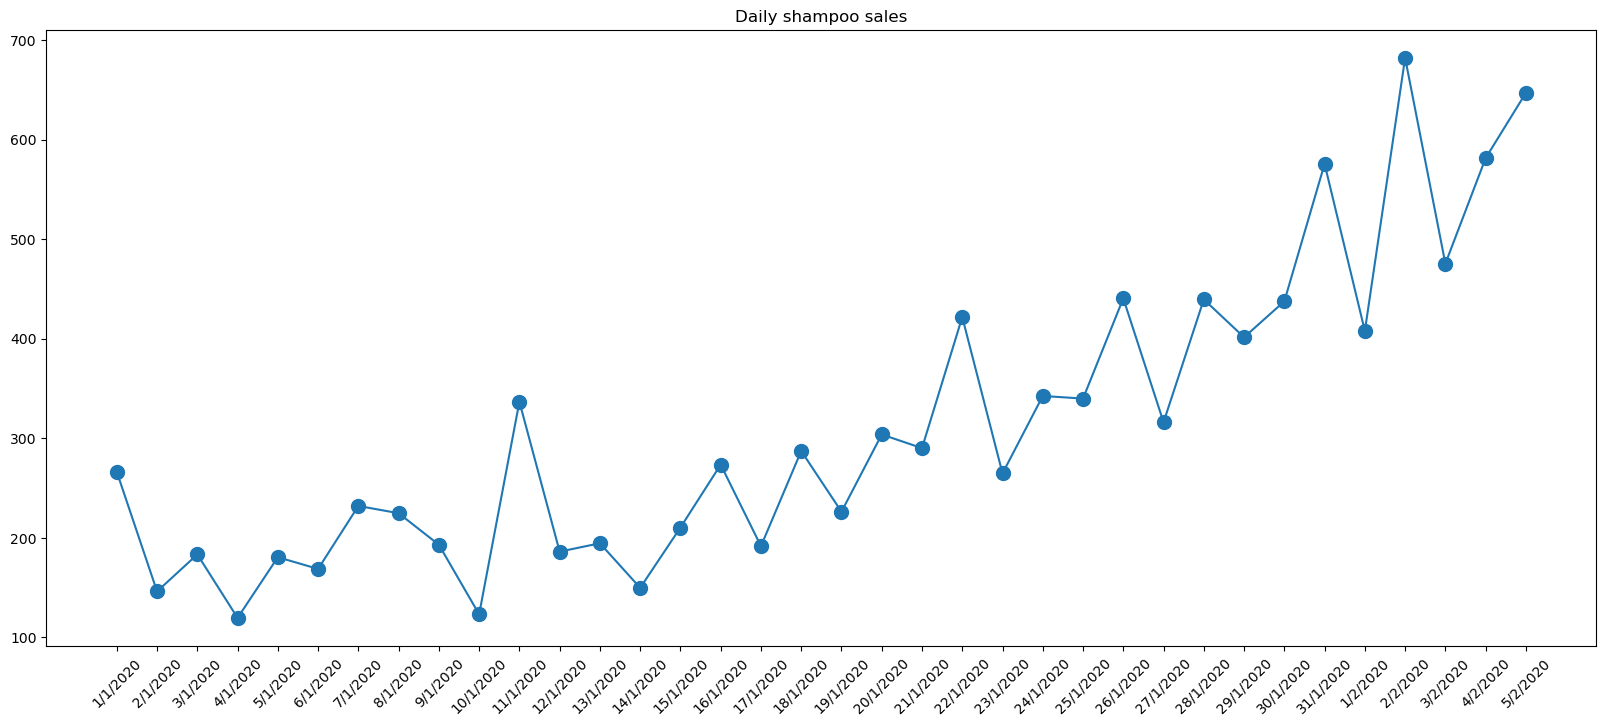

In [3]:
# plot the time series data
plt.figure(figsize = (20,8))
plt.plot(shampoo['Date'], shampoo['Sales'], '.-', markersize=20)
plt.title('Daily shampoo sales')
plt.xticks(rotation=45) # 👈 Add this line to rotate dates by 45 degrees
plt.show()

### Do you observe any trend or seasonality?

**Observation.** There is a clear upward trend but no obvious seasonality. A **Holt linear model** (exponential smoothing + trend) may therefore be appropriate. But we will try several different models anyway as benchmarks: moving average, simple exponential smoothing, Holt linear, and Holt-Winters.

Comparing these models on the same test set makes it possible to see which components — trend and/or seasonality — actually help.

In [4]:
# first split our data into training and test
train = shampoo[:-5] #"-5 index" means the last five records in this list.
test = shampoo[-5:]
train.shape, test.shape #first 31 records are used for training and the rest for testing

((31, 2), (5, 2))

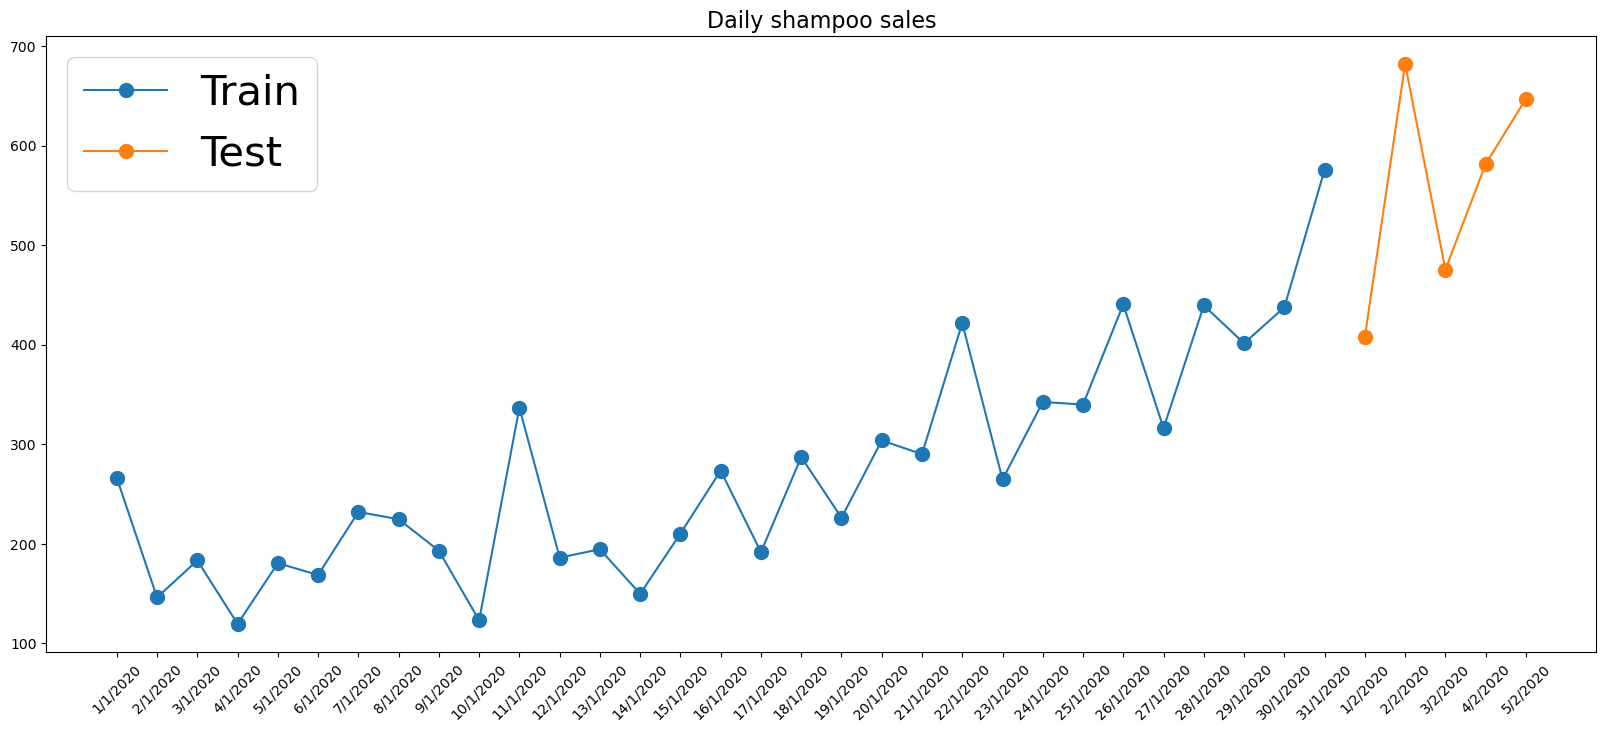

In [5]:
# plot training and testing data
plt.figure(figsize = (20,8))
plt.plot(train['Date'], train['Sales'], '.-',markersize=20,label = 'Train')
plt.plot(test['Date'], test['Sales'], '.-',markersize=20,label = 'Test')
plt.legend(loc = 'upper left',fontsize=30)
plt.title('Daily shampoo sales',fontsize=16)
plt.xticks(rotation=45) # 👈 Add this line to rotate dates by 45 degrees
plt.show()

### 1.1 Simple moving average

A simple moving average forecasts by averaging the most recent $w$ observations. In the tutorial, the forecast for the test period is the last available rolling average, held constant across the forecast horizon.

A moving average is a useful baseline, but it does **not** extrapolate a trend. If the series is rising, a flat moving-average forecast will tend to under-predict future values. The window size controls smoothness: a small window reacts faster but is noisier; a large window is smoother but reacts more slowly. The RMSE comparison below shows that the 5-window moving average performs best among the three moving-average benchmarks.

#### 1.1.1 window size of 5

In [6]:
#we can simply using the rolling window to calculate the moving average of this data
train['moving_average_5']=train['Sales'].rolling(5).mean() #window size of 5
train.head(31)

,Date,Sales,moving_average_5
0,1/1/2020,266.0,NaN
1,2/1/2020,145.9,NaN
2,3/1/2020,183.1,NaN
3,4/1/2020,119.3,NaN
4,5/1/2020,180.3,178.92
5,6/1/2020,168.5,159.42
6,7/1/2020,231.8,176.60
7,8/1/2020,224.5,184.88
8,9/1/2020,192.8,199.58
9,10/1/2020,122.9,188.10


In [7]:
#then we use the last window average as predicted value
test.loc[:,'moving_average_forecast_5'] = train['moving_average_5'].iloc[-1]
test.head()

,Date,Sales,moving_average_forecast_5
31,1/2/2020,407.6,433.88
32,2/2/2020,682.0,433.88
33,3/2/2020,475.3,433.88
34,4/2/2020,581.3,433.88
35,5/2/2020,646.9,433.88


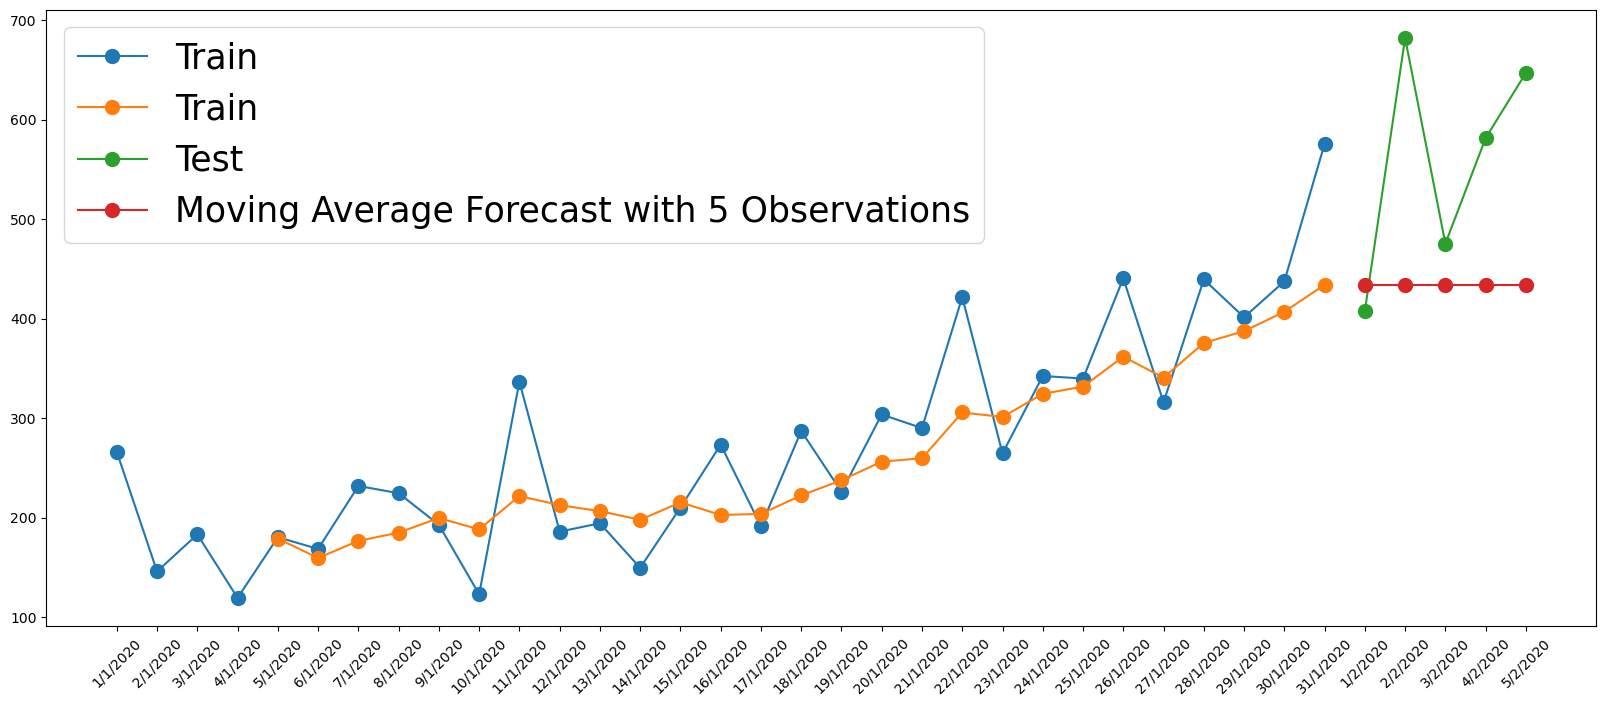

In [8]:

plt.figure(figsize = (20,8))
plt.plot(train['Date'], train['Sales'], '.-',markersize=20, label = 'Train')
plt.plot(train['Date'], train['moving_average_5'], '.-',markersize=20, label = 'Train')
plt.plot(test['Date'], test['Sales'],'.-',markersize=20, label = 'Test')
plt.plot(test['Date'], test['moving_average_forecast_5'],'.-',markersize=20, label = 'Moving Average Forecast with 5 Observations')
plt.legend(loc = 'upper left',fontsize=25)
plt.xticks(rotation=45) # 👈 Add this line to rotate dates by 45 degrees
plt.show()

#### 1.1.1 window size of 10

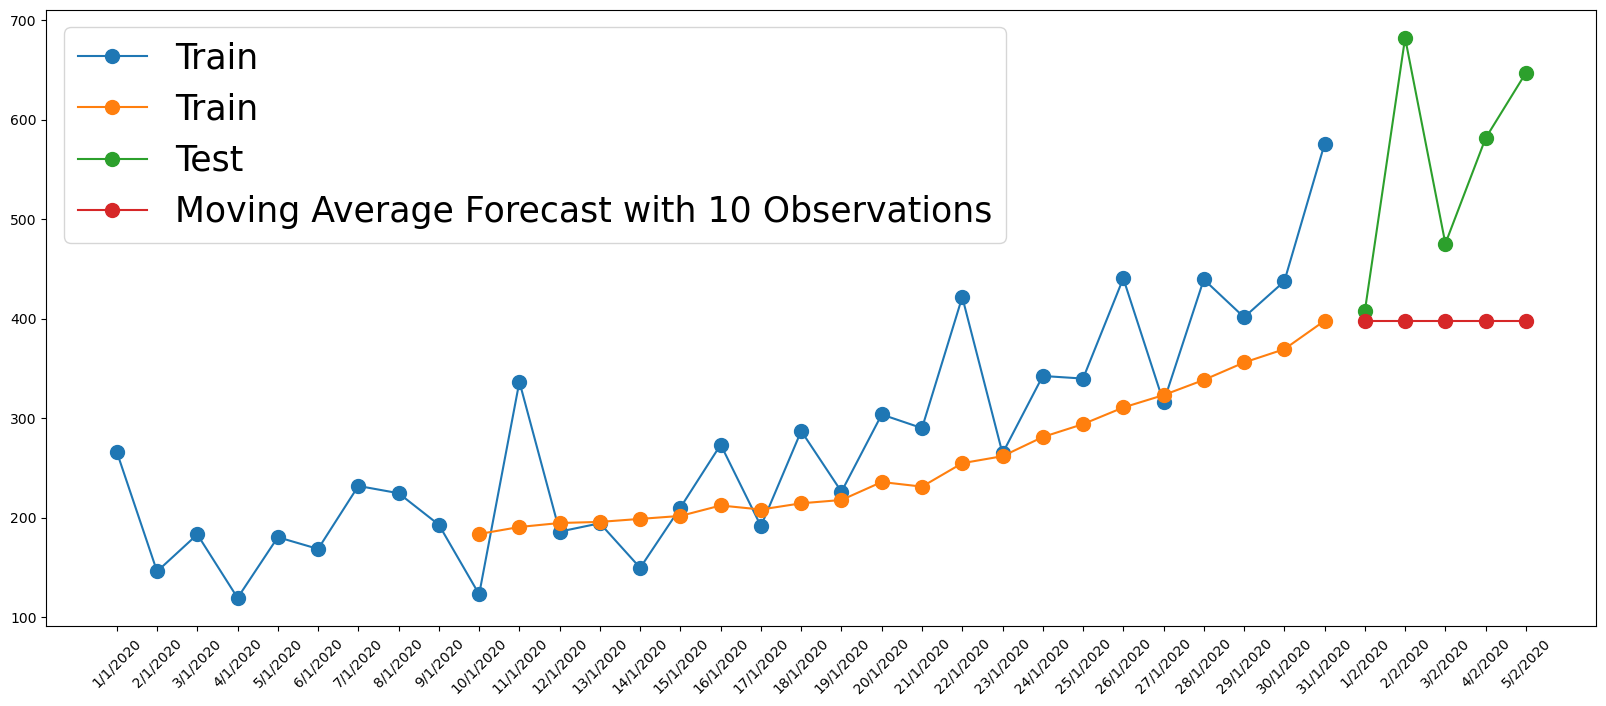

In [9]:
#let's switching to a moving window of size 10
train['moving_average_10']=train['Sales'].rolling(10).mean()
test['moving_average_forecast_10'] = train['moving_average_10'].iloc[-1]
plt.figure(figsize = (20,8))
plt.plot(train['Date'], train['Sales'], '.-',markersize=20, label = 'Train')
plt.plot(train['Date'], train['moving_average_10'], '.-',markersize=20, label = 'Train')
plt.plot(test['Date'], test['Sales'],'.-',markersize=20, label = 'Test')
plt.plot(test['Date'], test['moving_average_forecast_10'],'.-',markersize=20, label = 'Moving Average Forecast with 10 Observations')
plt.legend(loc = 'upper left',fontsize=25)
plt.xticks(rotation=45) # 👈 Add this line to rotate dates by 45 degrees
plt.show()

#### 1.1.1 window size of 15

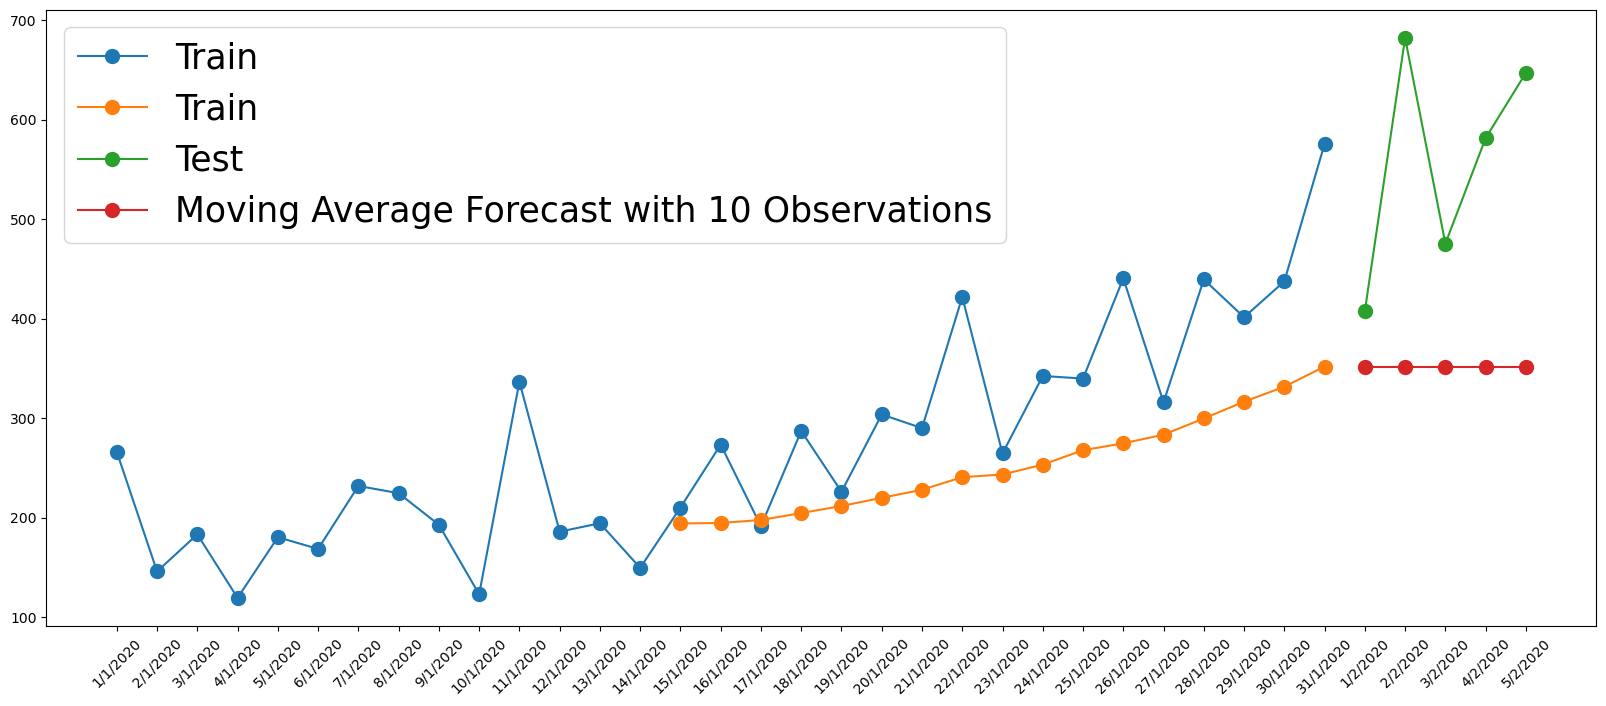

In [10]:
#let's switching to a moving window of size 15
train['moving_average_15']=train['Sales'].rolling(15).mean()
test['moving_average_forecast_15'] = train['moving_average_15'].iloc[-1]
plt.figure(figsize = (20,8))
plt.plot(train['Date'], train['Sales'], '.-',markersize=20, label = 'Train')
plt.plot(train['Date'], train['moving_average_15'], '.-',markersize=20, label = 'Train')
plt.plot(test['Date'], test['Sales'],'.-',markersize=20, label = 'Test')
plt.plot(test['Date'], test['moving_average_forecast_15'],'.-',markersize=20, label = 'Moving Average Forecast with 10 Observations')
plt.legend(loc = 'upper left',fontsize=25)
plt.xticks(rotation=45) # 👈 Add this line to rotate dates by 45 degrees
plt.show()

#### 1.1.4 Evaluation of different moving-average forecast

In [11]:
# get rmse of moving average with 5, 10, and 15 windows on test data
rmse_sma5 = np.sqrt(metrics.mean_squared_error(y_pred=test['moving_average_forecast_5'],
                                               y_true=test['Sales']))
rmse_sma10 = np.sqrt(metrics.mean_squared_error(y_pred=test['moving_average_forecast_10'],
                                                y_true=test['Sales']))
rmse_sma15 = np.sqrt(metrics.mean_squared_error(y_pred=test['moving_average_forecast_15'],
                                                y_true=test['Sales']))
print(rmse_sma5)
print(rmse_sma10)
print(rmse_sma15)

161.91353618521214
191.1078609058246
231.22183201419364


- **Interpretation of the moving-average RMSE results**

    - While the moving average with **5-window size** achieves the best performance among the three moving-average benchmarks, the overall performance is not very good. This is because a moving average does not capture trend patterns — it simply smooths the series and repeats a past average.

    - This motivates moving to exponential smoothing methods, which weight recent observations more heavily and can be extended with trend and seasonal components.

### 1.2 Simple exponential smoothing

Simple exponential smoothing (SES) estimates a **level** component only. It is appropriate when the series has no clear trend or seasonality. Because it has no trend term, its forecast is flat.

On the shampoo data, SES improves on the moving-average benchmarks but still cannot capture the upward trend. This is expected: SES deliberately omits the trend.

In [12]:
ses = ETSModel(train['Sales']) #by default, it is SEM
ses_fit = ses.fit()
y_predict = ses_fit.forecast(5)

RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            2     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  5.95479D+00    |proj g|=  8.99900D-01

At iterate    1    f=  5.92235D+00    |proj g|=  6.12009D-01

At iterate    2    f=  5.82759D+00    |proj g|=  4.77639D-01

At iterate    3    f=  5.74731D+00    |proj g|=  3.31424D-01

At iterate    4    f=  5.70308D+00    |proj g|=  7.62406D-02

At iterate    5    f=  5.70175D+00    |proj g|=  6.94875D-03

At iterate    6    f=  5.70174D+00    |proj g|=  7.81242D-04

At iterate    7    f=  5.70174D+00    |proj g|=  4.55635D-05

At iterate    8    f=  5.70174D+00    |proj g|=  8.61533D-05

At iterate    9    f=  5.70174D+00    |proj g|=  4.70912D-04

At iterate   10    f=  5.70174D+00    |proj g|=  1.04476D-03

At iterate   11    f=  5.70174D+00    |proj g|=  2.00604D-03

At iterate   12    f=  5.70174D+00    |proj g|=  3.53158D-03

At iterate   13    f=  5.7

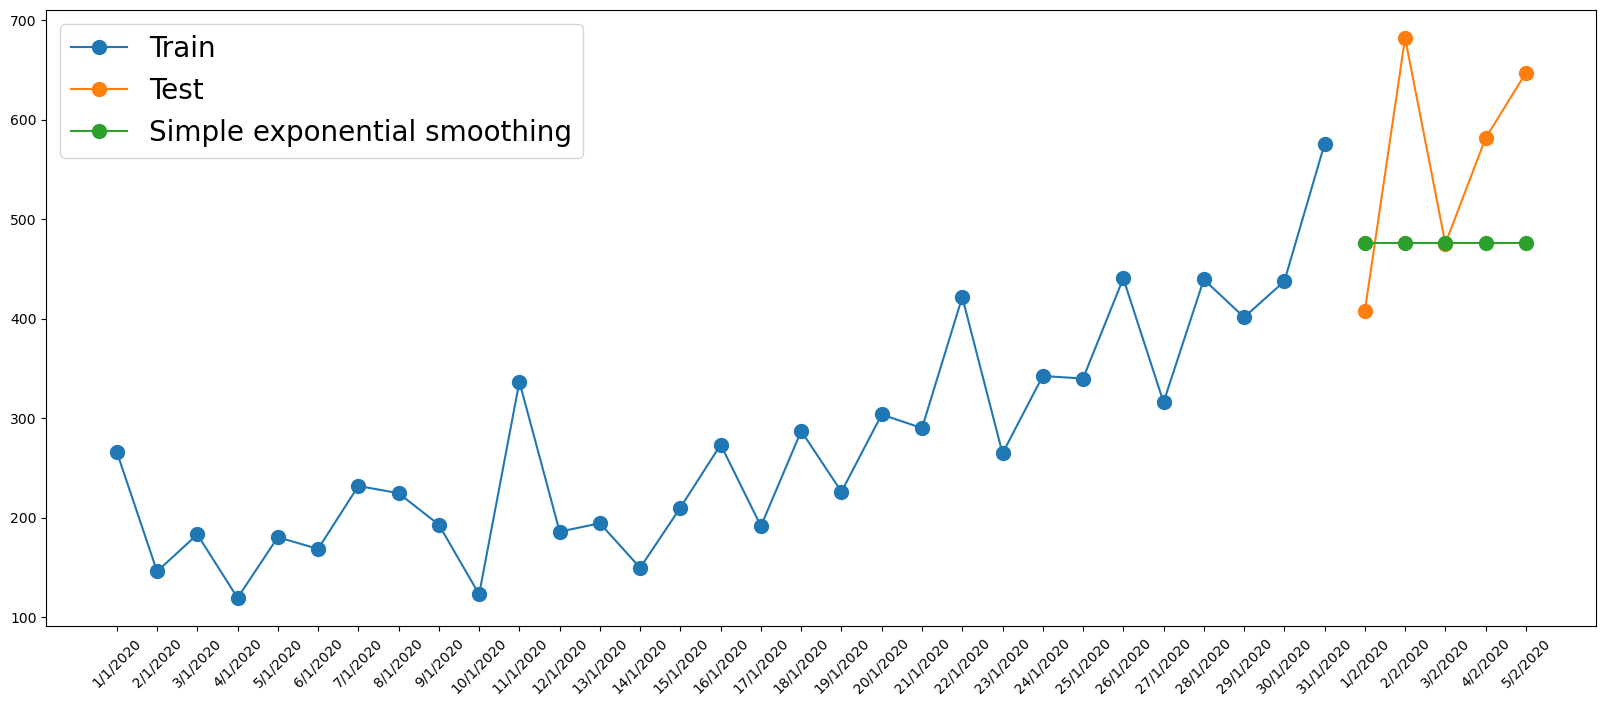

In [13]:
plt.figure(figsize = (20,8))
plt.plot(train['Date'], train['Sales'],'.-',markersize=20, label = 'Train')
plt.plot(test['Date'], test['Sales'],'.-',markersize=20, label = 'Test')
plt.plot(test['Date'], y_predict,'.-',markersize=20, label = 'Simple exponential smoothing')
plt.legend(loc = 'upper left',fontsize=20)
plt.xticks(rotation=45) # 👈 Add this line to rotate dates by 45 degrees
plt.show()

In [14]:
rmse_ses = np.sqrt(metrics.mean_squared_error(y_pred=y_predict, y_true=test['Sales']))
print(rmse_ses)

132.54521896368806


### 1.3 Holt linear trend

Holt's linear method adds a **trend** component to simple exponential smoothing. This is well matched to the shampoo series, which has a clear upward trend.

In the tutorial, setting `trend='add'` allows the forecast to continue the estimated trend rather than remaining flat. Holt therefore achieves the lowest RMSE on the shampoo test set among the models considered so far.

In [15]:
holt = ETSModel(train['Sales'], trend='add') #we use linear by adding addictive trend pattern
holt_fit = holt.fit()
y_predict = holt_fit.forecast(5)

RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            4     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  5.86122D+00    |proj g|=  8.99900D-01

At iterate    1    f=  5.64762D+00    |proj g|=  3.36933D-01

At iterate    2    f=  5.58677D+00    |proj g|=  1.81681D-01

At iterate    3    f=  5.57372D+00    |proj g|=  2.09902D-01

At iterate    4    f=  5.56084D+00    |proj g|=  1.38460D-01

At iterate    5    f=  5.55240D+00    |proj g|=  9.15892D-01

At iterate    6    f=  5.53636D+00    |proj g|=  8.72221D-02

At iterate    7    f=  5.52799D+00    |proj g|=  6.89924D-01

At iterate    8    f=  5.52704D+00    |proj g|=  6.46732D-02

At iterate    9    f=  5.52651D+00    |proj g|=  3.59178D-01

At iterate   10    f=  5.52593D+00    |proj g|=  1.80767D-02

At iterate   11    f=  5.52593D+00    |proj g|=  2.16405D-03

At iterate   12    f=  5.52593D+00    |proj g|=  8.88356D-04

At iterate   13    f=  5.5

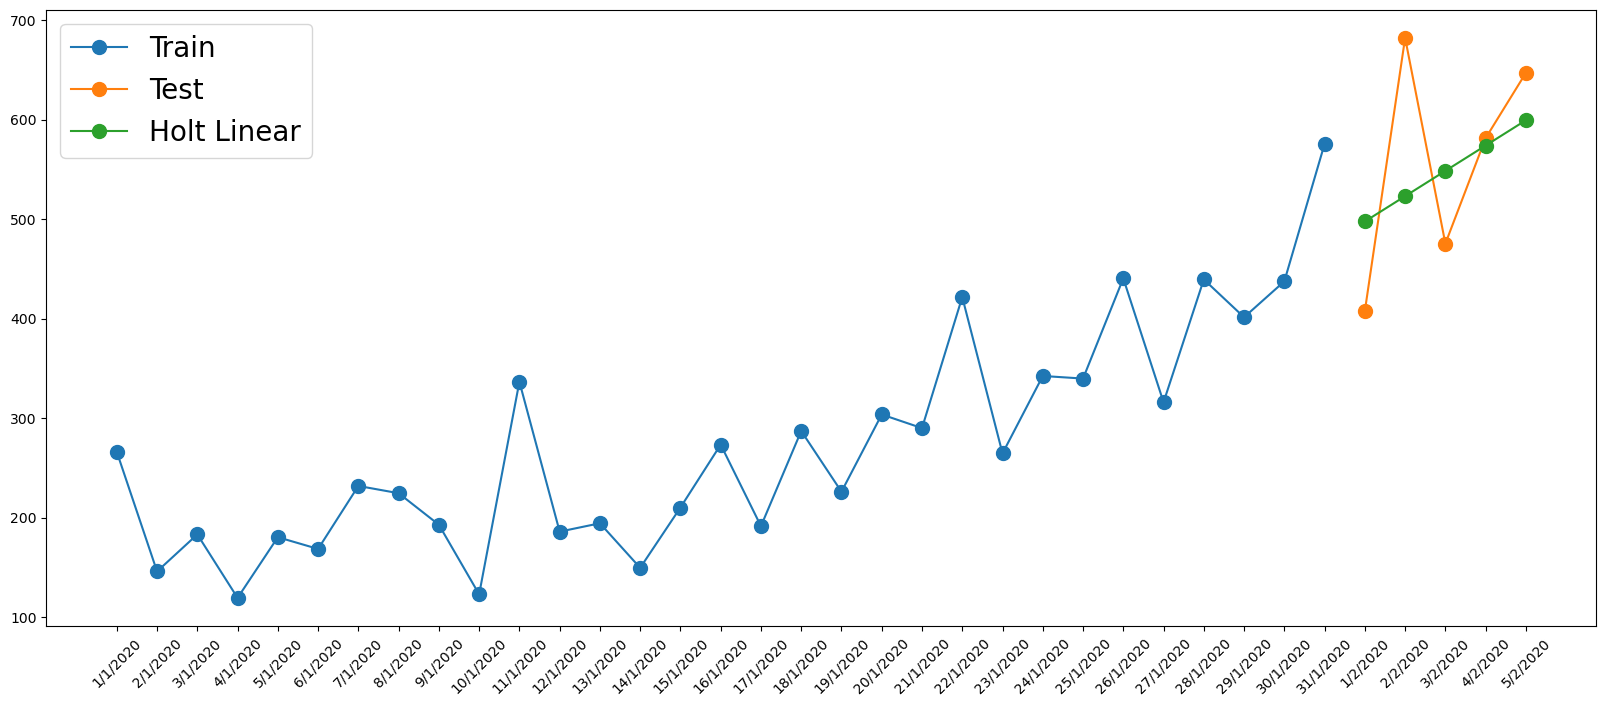

In [16]:
plt.figure(figsize = (20,8))
plt.plot(train['Date'], train['Sales'],'.-',markersize=20, label = 'Train')
plt.plot(test['Date'], test['Sales'],'.-',markersize=20, label = 'Test')
plt.plot(test['Date'], y_predict,'.-',markersize=20, label = 'Holt Linear')
plt.legend(loc = 'upper left',fontsize=20)
plt.xticks(rotation=45) # 👈 Add this line to rotate dates by 45 degrees
plt.show()

In [17]:
rmse_holt = np.sqrt(metrics.mean_squared_error(y_pred=y_predict, y_true=test['Sales']))
print(rmse_holt)

90.60615415152297


### 1.4 Holt-Winters

Holt-Winters adds a **seasonal** component to Holt's linear trend. In the tutorial, `seasonal='add'` and `seasonal_periods=4` are used to illustrate a seasonal ETS model.

However, the shampoo series does not show clear seasonality. Adding a seasonal component therefore does not improve the forecast and can make the model unnecessarily complex. This illustrates an important modelling principle: **only include a seasonal component when the data show a genuine seasonal pattern.**

In [18]:
holt = ETSModel(train['Sales'], trend='add',seasonal = 'add', seasonal_periods = 4) 
holt_fit = holt.fit()
y_predict = holt_fit.forecast(5)

RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            8     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  5.76954D+00    |proj g|=  6.41932D-01

At iterate    1    f=  5.72442D+00    |proj g|=  2.64048D-01

At iterate    2    f=  5.71358D+00    |proj g|=  1.50859D-01

At iterate    3    f=  5.70588D+00    |proj g|=  1.53106D-01

At iterate    4    f=  5.69888D+00    |proj g|=  3.71001D-01

At iterate    5    f=  5.68883D+00    |proj g|=  1.44499D-01

At iterate    6    f=  5.67609D+00    |proj g|=  6.17493D-02

At iterate    7    f=  5.67174D+00    |proj g|=  2.58964D-01

At iterate    8    f=  5.66637D+00    |proj g|=  1.58748D-01

At iterate    9    f=  5.66283D+00    |proj g|=  1.40848D-01

At iterate   10    f=  5.66261D+00    |proj g|=  2.58678D-02

At iterate   11    f=  5.66258D+00    |proj g|=  1.33980D-02

At iterate   12    f=  5.66258D+00    |proj g|=  3.46692D-03

At iterate   13    f=  5.6

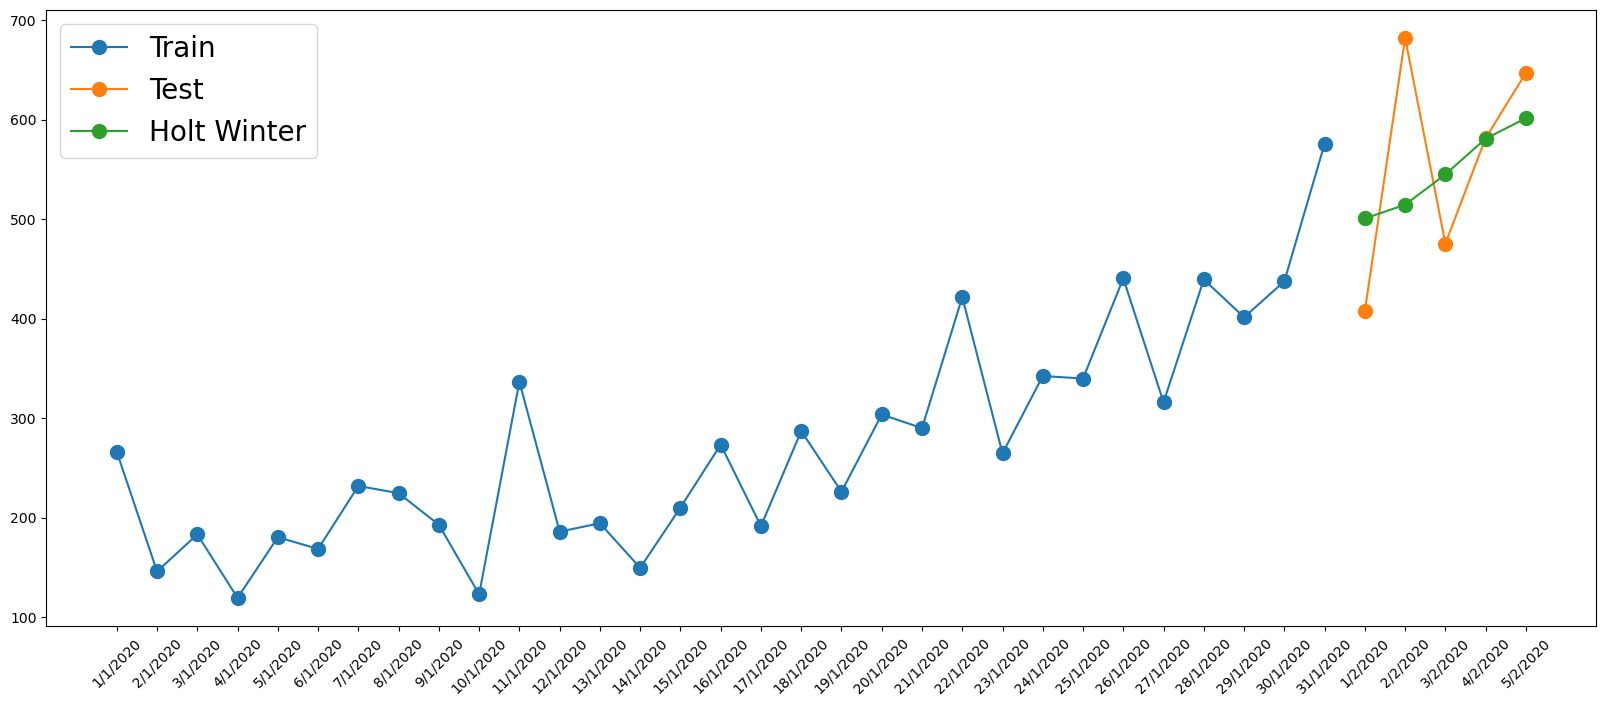

In [19]:
plt.figure(figsize = (20,8))
plt.plot(train['Date'], train['Sales'],'.-',markersize=20, label = 'Train')
plt.plot(test['Date'], test['Sales'],'.-',markersize=20, label = 'Test')
plt.plot(test['Date'], y_predict,'.-',markersize=20, label = 'Holt Winter')
plt.legend(loc = 'upper left',fontsize=20)
plt.xticks(rotation=45) # 👈 Add this line to rotate dates by 45 degrees
plt.show()

In [20]:
rmse_holt = np.sqrt(metrics.mean_squared_error(y_pred=y_predict, y_true=test['Sales']))
print(rmse_holt)

93.4527830011457


## 2. Quarterly cardiovascular deaths (CVD)

The CVD series is quarterly, so a natural seasonal period is 4. Unlike the shampoo data, the CVD plot shows a repeating within-year pattern. This makes the CVD data a good example for comparing non-seasonal and seasonal exponential smoothing models.

The tutorial fits:

- **simple exponential smoothing** — no trend, no seasonality;
- **Holt linear trend** — adds a trend component;
- **Holt-Winters** — adds both trend and additive seasonality.

The RMSE results show the expected pattern: simple exponential smoothing performs worst because it ignores both trend and seasonality; Holt linear improves slightly; Holt-Winters improves substantially because it captures the quarterly seasonal pattern.

In [21]:
# import the data
cvd = pd.read_csv('CVD.csv')
cvd.head()

,year,quarter,cvd
0,1987,1,4761
1,1987,2,4217
2,1987,3,3950
3,1987,4,4639
4,1988,1,5354


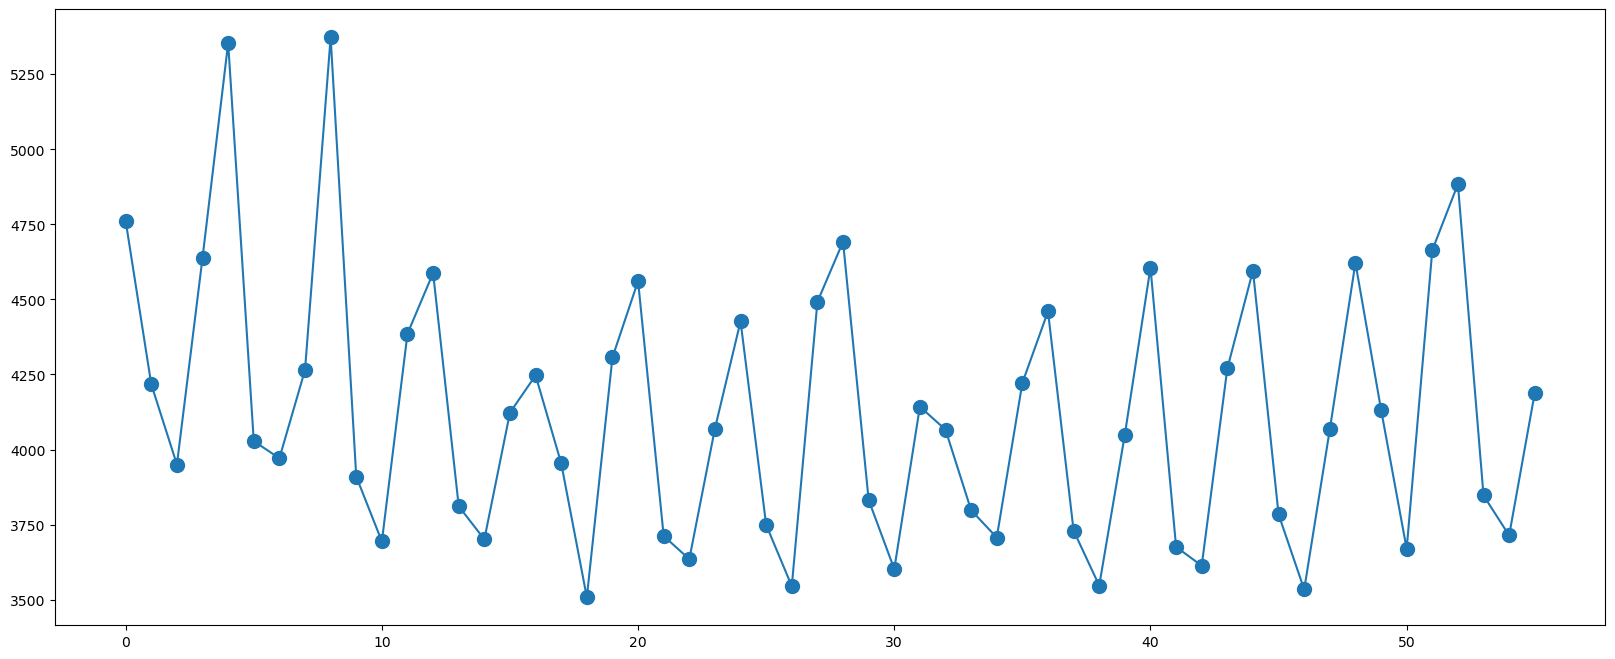

In [22]:
# plot the data
plt.figure(figsize = (20,8))
plt.plot(cvd['cvd'],'.-',markersize=20)
plt.show()

### Let us try different exponential smoothing methods

We now split the CVD data into 90% training and 10% testing, then fit three ETS variants. By comparing RMSE across the three models, we can see the effect of adding trend and seasonal components.

In [23]:
# let's first split our data into 90% training and 10% testing
N_train = int(0.9*cvd.shape[0])
N_test = cvd.shape[0] - N_train
print(N_train)
print(N_test)

50
6


In [24]:
cvd_train = cvd[:N_train] # take first N_train (50) data as trainig data
cvd_test = cvd[N_train:] # the remaining N_test (6) data as test data

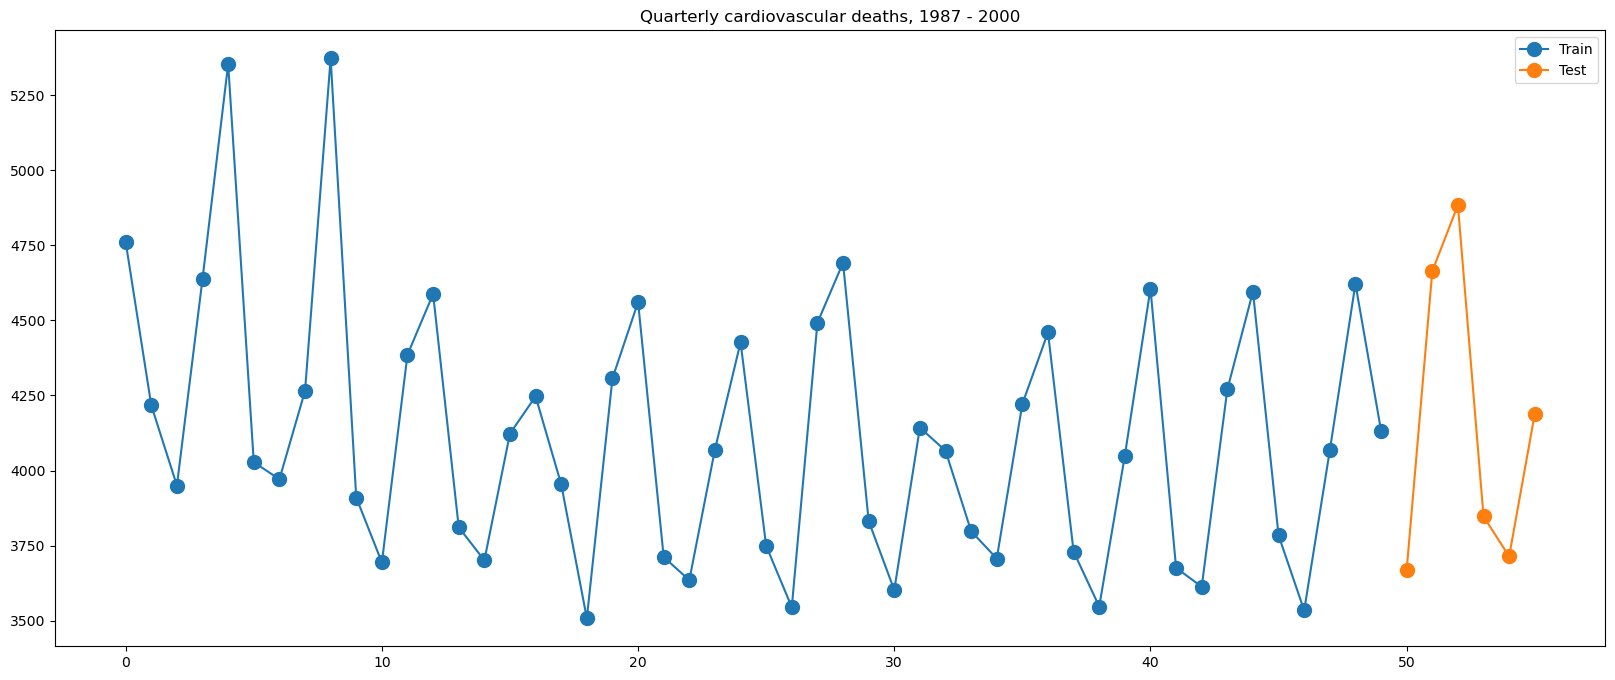

In [25]:
plt.figure(figsize = (20,8))
plt.plot(cvd_train['cvd'],'.-',markersize=20, label = 'Train')
plt.plot(cvd_test['cvd'],'.-',markersize=20, label = 'Test')
plt.legend(loc = 'upper right')
plt.title('Quarterly cardiovascular deaths, 1987 - 2000')
plt.show()

### 2.1 Simple exponential smoothing

As a baseline, we fit simple exponential smoothing. On a seasonal series, a flat forecast is clearly inadequate: it ignores the repeating quarterly pattern and produces a high RMSE.

In [26]:
ses = ETSModel(cvd_train['cvd']) 
ses_fit = ses.fit()
y_predict = ses_fit.forecast(N_test)

RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            2     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  7.52238D+00    |proj g|=  9.15334D-02

At iterate    1    f=  7.52197D+00    |proj g|=  1.45373D-02

At iterate    2    f=  7.52196D+00    |proj g|=  1.78346D-03

At iterate    3    f=  7.52196D+00    |proj g|=  8.03810D-05

At iterate    4    f=  7.52196D+00    |proj g|=  8.02922D-05

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
    2      4      6      4     0     0   8.029D-05   7.522D+00
  F =   7.5219596168568437     

CONVERG

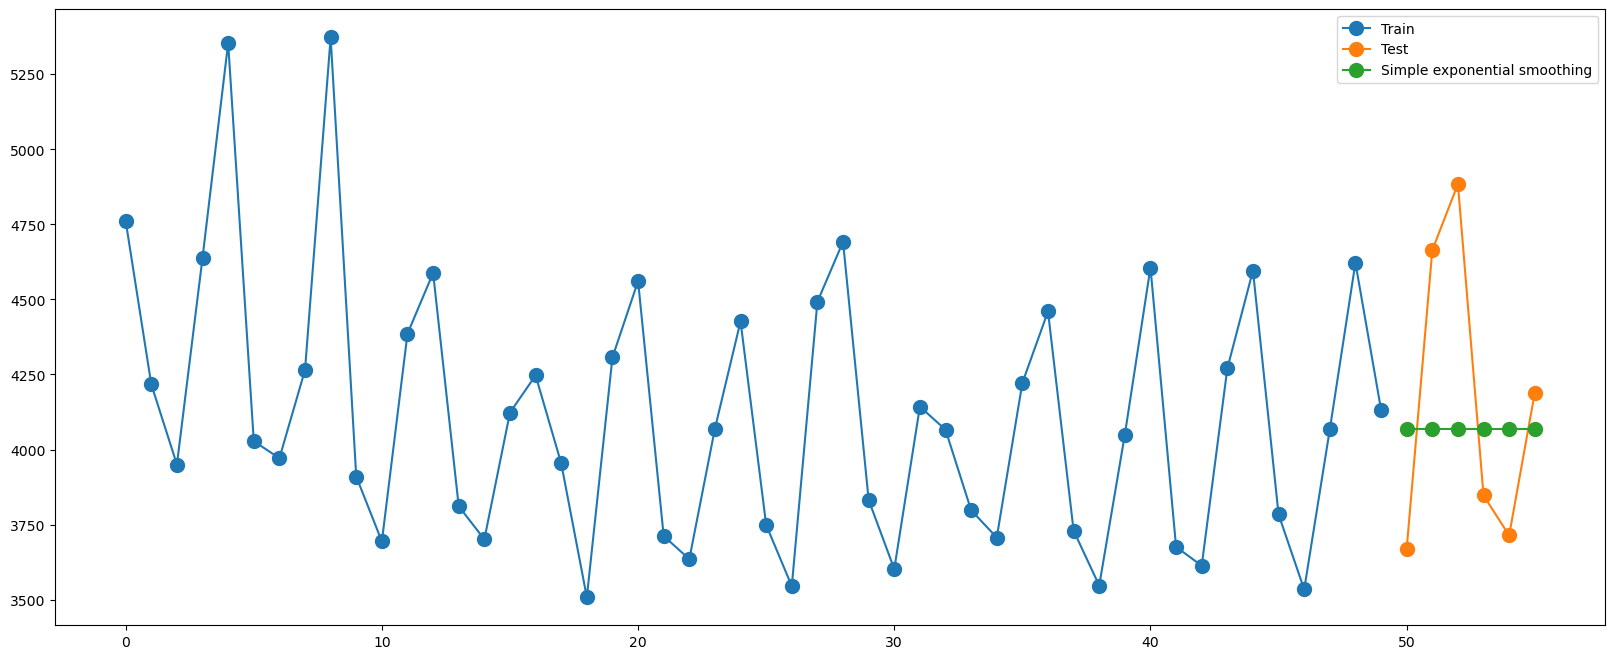

In [27]:
plt.figure(figsize = (20,8))
plt.plot(cvd_train['cvd'],'.-',markersize=20, label = 'Train')
plt.plot(cvd_test['cvd'],'.-',markersize=20, label = 'Test')
plt.plot(y_predict,'.-',markersize=20, label = 'Simple exponential smoothing')
plt.legend(loc = 'upper right')
plt.show()

In [28]:
rmse_ses = np.sqrt(metrics.mean_squared_error(y_pred=y_predict, y_true=cvd_test['cvd']))
print(rmse_ses)

477.6302891214218


### 2.2 Holt linear

Holt's linear method adds a trend component. On the CVD data, the trend is relatively mild, so the improvement over simple exponential smoothing is modest. The seasonal pattern is still not captured, which limits the accuracy of the forecast.

RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            4     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  7.51731D+00    |proj g|=  6.46149D-02

At iterate    1    f=  7.51706D+00    |proj g|=  3.51632D-02

At iterate    2    f=  7.51674D+00    |proj g|=  4.44582D-02

At iterate    3    f=  7.51624D+00    |proj g|=  9.22004D-02

At iterate    4    f=  7.51508D+00    |proj g|=  2.59308D-01

At iterate    5    f=  7.51356D+00    |proj g|=  3.23764D-01

At iterate    6    f=  7.51122D+00    |proj g|=  9.75762D-03

At iterate    7    f=  7.51121D+00    |proj g|=  4.87166D-03

At iterate    8    f=  7.51121D+00    |proj g|=  1.28910D-03

At iterate    9    f=  7.51121D+00    |proj g|=  1.28706D-03

At iterate   10    f=  7.51120D+00    |proj g|=  9.93445D-03

At iterate   11    f=  7.51119D+00    |proj g|=  1.93453D-02

At iterate   12    f=  7.51115D+00    |proj g|=  3.70306D-02

At iterate   13    f=  7.5

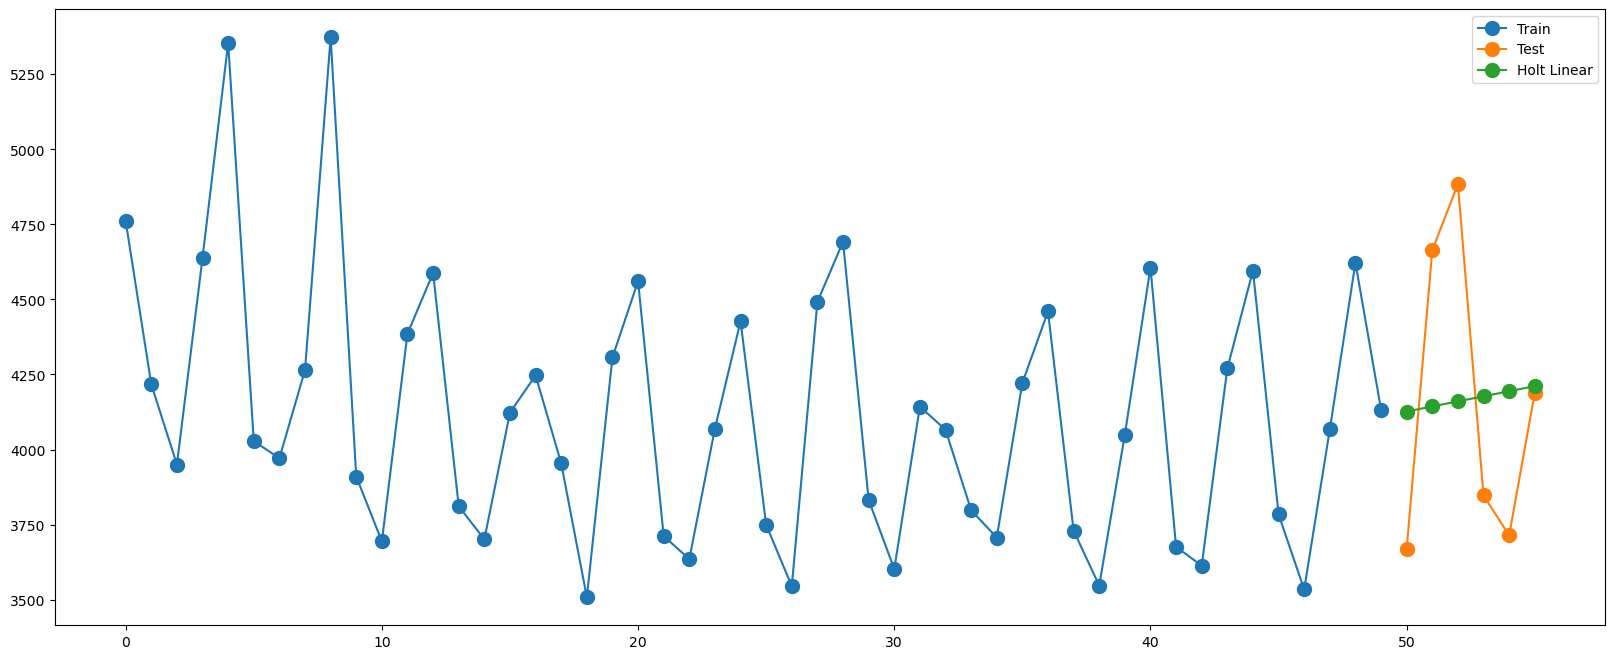

473.29701380363144


In [29]:
ses = ETSModel(cvd_train['cvd'], trend='add') 
ses_fit = ses.fit()
y_predict = ses_fit.forecast(N_test)

plt.figure(figsize = (20,8))
plt.plot(cvd_train['cvd'],'.-',markersize=20, label = 'Train')
plt.plot(cvd_test['cvd'],'.-',markersize=20, label = 'Test')
plt.plot(y_predict,'.-',markersize=20, label = 'Holt Linear')
plt.legend(loc = 'upper right')
plt.show()

rmse_ses = np.sqrt(metrics.mean_squared_error(y_pred=y_predict, y_true=cvd_test['cvd']))
print(rmse_ses)

### 2.3 Holt-Winters

Holt-Winters adds both trend and additive seasonal components. On the CVD data, this captures the repeating quarterly pattern and produces a much lower RMSE than the non-seasonal methods. This is the expected outcome: the CVD series has a clear seasonal pattern, so a seasonal model is appropriate.

RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            8     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  7.43068D+00    |proj g|=  9.88789D-01

At iterate    1    f=  7.04736D+00    |proj g|=  2.09554D-01

At iterate    2    f=  6.99378D+00    |proj g|=  1.92347D-01

At iterate    3    f=  6.98139D+00    |proj g|=  1.66165D-01

At iterate    4    f=  6.96896D+00    |proj g|=  4.60620D-01

At iterate    5    f=  6.95738D+00    |proj g|=  5.47265D-02

At iterate    6    f=  6.95620D+00    |proj g|=  4.83141D-02

At iterate    7    f=  6.95603D+00    |proj g|=  2.30238D-02

At iterate    8    f=  6.95598D+00    |proj g|=  2.44539D-02

At iterate    9    f=  6.95584D+00    |proj g|=  3.83181D-02

At iterate   10    f=  6.95547D+00    |proj g|=  7.09034D-02

At iterate   11    f=  6.95483D+00    |proj g|=  1.13039D-01

At iterate   12    f=  6.95391D+00    |proj g|=  1.02561D-01

At iterate   13    f=  6.9

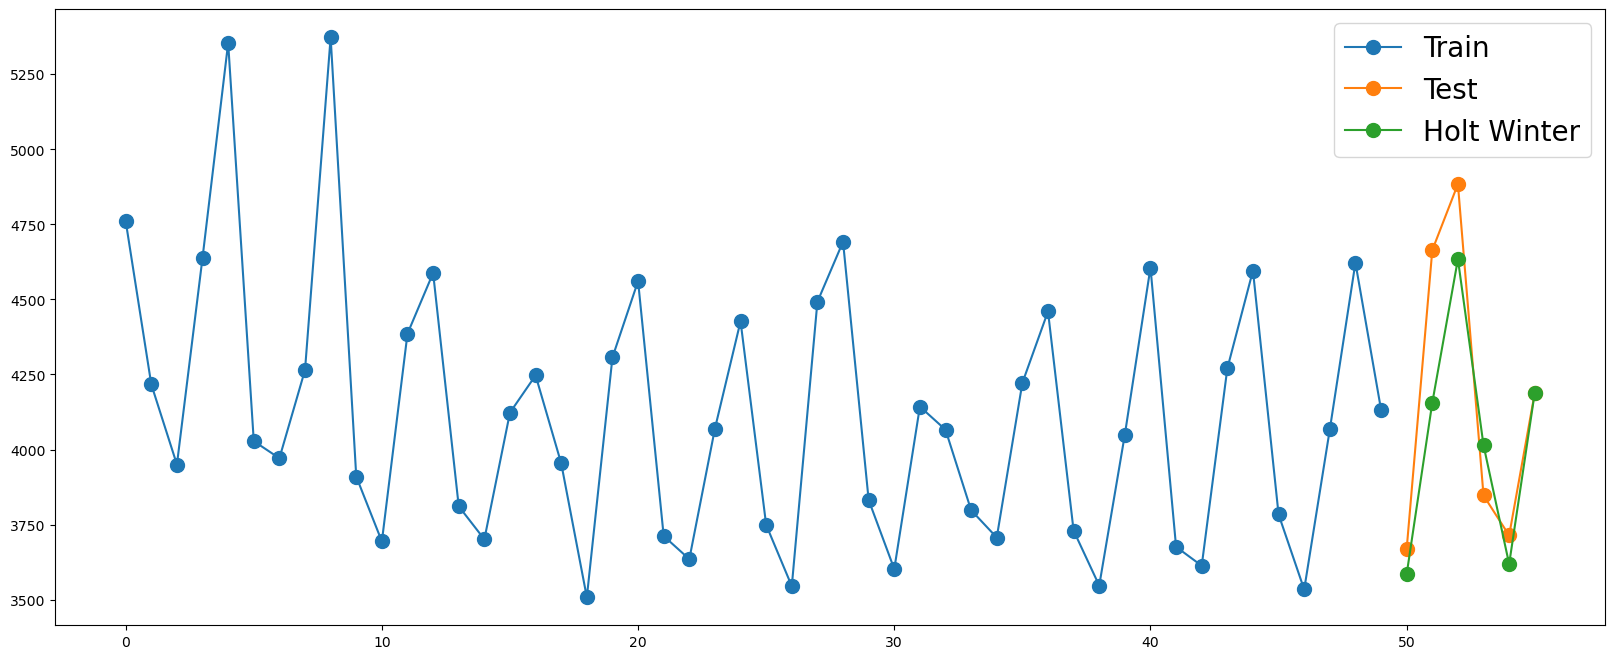

246.58441437926794


In [30]:
hw = ETSModel(cvd_train['cvd'], trend='add', seasonal = 'add', seasonal_periods = 4)
hw_fit = hw.fit()
y_predict = hw_fit.forecast(N_test)

plt.figure(figsize = (20,8))
plt.plot(cvd_train['cvd'],'.-',markersize=20, label = 'Train')
plt.plot(cvd_test['cvd'],'.-',markersize=20, label = 'Test')
plt.plot(y_predict,'.-',markersize=20, label = 'Holt Winter')
plt.legend(loc = 'upper right',fontsize=20)
plt.show()

rmse_hw = np.sqrt(metrics.mean_squared_error(y_pred=y_predict, y_true=cvd_test['cvd']))
print(rmse_hw)

# Assignment Week 8 

Bitcoin is a cryptocurrency. Its price has increased dramatically in the past five years. The file `Q5BTC-USD.csv` contains Bitcoin close prices from 30/04/2013 to 30/04/2018 in the column `Close`. Use this data set to answer the following questions.

**(1)** If you are asked to use autoregressive models to generate forecasting, which variable do you think will work better as the dependent variable, and why? (20 pts)

- (a) The original value of Bitcoin prices `Close_t`, or  
- (b) The first-order differenced value `D_Close_t = Close_t - Close_{t-1}`.

**(2)** Please fit a basic ETS model (without trend and seasonal components) to forecast Bitcoin Prices for the next five trading days. Hold out the last five trading days as the test set, report the forecasted prices (keep the answers to two decimal places), and calculate the RMSE.(20 pts)

**(3)** Please fit an ETS model that includes a trend component to forecast Bitcoin Prices for the next five trading days.
Hold out the last five trading days as the test set, report the forecasted prices (keep the answers to two decimal places), and calculate the RMSE.
Compare the results (both the forecasted values and the RMSE) with the model in Question 2. Based on your comparison, discuss which model is more suitable for this specific dataset and explain why.(40 pts)

**(4)** Design a rolling-forecasting evaluation method to evaluate the "next-day" prediction performance. Please illustrate the validation dataset, evaluation metrics and calculation, and model comparison in your method. (This is a method-design question; no programming is needed.) (20 points)

## Submission Guidelines

Please submit **ONE new, comprehensive and fully executable document** for Questions 1 to 4.

**Content Requirements:**
*   **Clearly label** each question (Q1, Q2, Q3, Q4).
*   **Q2 & Q3:** Include the **complete, runnable Python code** and print the final outputs (forecasts and RMSE).
*   **Written Answers:** Provide clear written explanations for Q1, the model comparison in Q3, and the method design in Q4 (no coding needed for Q4).

**File Format & Submission:**
*   **Export as HTML:** Save your final document (including code, outputs, and text) as an **HTML file**. (In Jupyter: `File` -> `Download as` -> `HTML`).
*   **Upload:** Submit the `.html` file to Canvas.